# Jupiter impact pipeline

Runs the full pipeline from `jupiter_impact_model.py` (Hueso et al. 2018) one step at a time:

1. **Settings**: edit these for each event
2. **Part 0**: observing geometry (JPL Horizons), emission angle, and cloud reflection factor `fcr`
3. **Part A**: extract the light curve from the video frames
4. **Part B**: impact energy and impactor properties
5. **Outputs**: impact stack, corrected light curves, CSVs, results table

Run the cells top to bottom. After changing a setting, re-run from that cell down.
All functions live in `jupiter_impact_model.py`, which must be in the same folder as this notebook.

In [40]:
%reload_ext autoreload
%autoreload 2 
# autoreload makes it so kernel does not need to be restarted when changes are made to jupiter_impact_model.py

import os
import numpy as np
import pandas as pd
from IPython.display import Image, display
''' sys import needed if working in a folder different from jupiter_impact_model.py '''
import sys
sys.path.insert(0, os.path.abspath("..")) # folder containing jupiter_impact_model.py


from jupiter_impact_model import (
    KT_TO_J,
    get_jupiter_geometry,
    compute_mu,
    load_DHG_parameters,
    load_camera_response,
    compute_fCR_combined,
    plot_DHG_parameters,
    plot_fCR_lambertian,
    plot_delta_ICR,
    plot_delta_ICR_DHG,
    extract_light_curve,
    measure_I_jupiter,
    jupiter_impact_model,
    jupiter_impact_model_from_watts,
    camera_filter_response,
    corrected_light_curve,
    save_impact_stack,
    plot_aperture_diagnostic,
    plot_flash_difference,
    plot_difference_histogram,
    plot_light_curve_DN,
    plot_corrected_light_curves,
    print_results_table,
)

# jupiter_impact_model.py switches matplotlib to the non-interactive "Agg"
# backend on import; switch back so plots display in the notebook
%matplotlib inline

## Settings: redefine these for each event

- **Input files**: rename if your files are named differently. `QE_CSVS` has one CSV per camera channel; use a one-item list for a monochrome camera. Frames must be named `frame%03d.png`.
- **Event**: observation time and site are used to query JPL Horizons. The impact site's planetographic latitude and System III longitude are measured from the images (e.g. with WinJUPOS).
- **Cloud reflection**: `FCR_METHOD = "DHG"` computes `fcr` with the full Arimatsu et al. (2023) model (about 25 s). Use `"manual"` to set `FCR_MANUAL` directly.
- **Photometry**: check these against the aperture diagnostic plot in Part A.

In [25]:
# ---- Event ------------------------------------------------------------------
OBS_TIME_UTC      = "2023-11-15 12:41:17"
# MPC observatory code ("500" = geocenter) or {"lon": deg, "lat": deg, "elevation": km}
OBSERVER_LOCATION = {"lon": 139.6380, "lat": 35.4437, "elevation": 0.013}
''' Find impact lat/lon from WinJUPOS '''
impact_lat        = 10.7     # planetographic latitude of impact site [deg]
impact_lon        = 343.9    # System III longitude of impact site [deg]

# Set USE_HORIZONS = False to skip the online query and use MANUAL_GEOMETRY values instead
USE_HORIZONS    = True
MANUAL_GEOMETRY = {"d_jupiter_au": 4.9766, "V_jupiter": -2.89,
                   "subobs_lat": 3.7961, "subobs_lon": 33.5696}

# ---- Input files ----------------------------------------------------------
FRAME_DIR        = "./frames"
SOLAR_CSV        = "../solar_spectrum.csv" # Colina et al. (1996)
ALBEDO_CSV       = "../albedo.csv"   # Karkoschka (1994) # alternative: "./li2018_pg.csv"
QE_CSVS          = ["./B.csv",
                    "./V.csv",
                    "./R.csv"] # From camera set to NONE if no camera QE
TRANSMISSION_CSV = "./transmission.csv" # Filter transmission set to NONE if no filter used
DHG_CSVS         = {"omega": "../omega.csv", "g1": "../g1.csv",
                    "g2": "../g2.csv", "f": "../f.csv"}   # Heng & Li (2021)
PG_CSV           = "../li2018_pg.csv"   # geometric albedo, for the optional Lambertian plot

# ---- Cloud reflection -------------------------------------------------------
FCR_METHOD      = "DHG"    # "DHG" or "manual" to set it by hand
FCR_MANUAL      = 1.83     # used only when FCR_METHOD = "manual"
flash_height_km = 50.0     # flash height above the clouds [km]

# ---- Photometry -------------------------------------------------------------
aperture_radius = 11.5   # should encompass the entire impact PSF - check "Aperture Diagnostic" cell
sky_inner       = 18.0
sky_outer       = 30.0

# ---- Light curve extraction ------------------------------------------------
quiet_fraction   = 0.6   # fraction of quietest frames used for the reference image
flash_frames     = (48, 140) # manually perscribed flash frames - more accurate than n_sigma
n_sigma          = 1.0   # flash detection threshold - not used is flash frames are defined
savgol_window    = 10    # 0 to skip smoothing
savgol_polyorder = 4

# ---- Camera -----------------------------------------------------------------
fps = 40   # camera frame rate

# ---- Physical assumptions ---------------------------------------------------
T_flash_range_K = (6000.0, 14000.0) # Blackbody temperature range [K]
v_kms_values    = [60.0, 65.0, 70.0]        # impact velocities [km/s]
density_values  = [500.0, 2500.0, 5000.0]   # impactor densities [kg/m³]

# ---- Wavelength range [nm] --------------------------------------------------
lam_min_nm = 400.0 # Filter wavelength range or camera wavelength range if no filter
lam_max_nm = 1000.0

Checks which spectral and camera files exist. Missing files fall back to the generic analytic curves.

In [26]:
using_spectra = os.path.exists(SOLAR_CSV) and os.path.exists(ALBEDO_CSV)
# The filter is optional: without a transmission file the QE curves are used alone.
# A filter without QE curves can't be used, so that case falls back to the generic camera.
using_qe     = all(os.path.exists(p) for p in QE_CSVS)
using_filter = using_qe and TRANSMISSION_CSV is not None and os.path.exists(TRANSMISSION_CSV)

qe_csvs          = QE_CSVS          if using_qe      else None
transmission_csv = TRANSMISSION_CSV if using_filter  else None
solar_csv        = SOLAR_CSV        if using_spectra else None
albedo_csv       = ALBEDO_CSV       if using_spectra else None

print(f"Solar/albedo spectra : {'tabulated CSVs' if using_spectra else 'analytic fallback'}")
if using_filter:
    camera_desc = "tabulated QE + filter transmission"
elif using_qe:
    camera_desc = "tabulated QE, no filter"
else:
    camera_desc = "generic fallback"
print(f"Camera + filter      : {camera_desc}")

Solar/albedo spectra : tabulated CSVs
Camera + filter      : tabulated QE + filter transmission


## Part 0: observing geometry and cloud reflection

### Jupiter's geometry from JPL Horizons

Gives the Jupiter–Sun distance, Jupiter's apparent magnitude, and the sub-observer point at the time of the impact. Needs an internet connection; set `USE_HORIZONS = False` in Settings to use `MANUAL_GEOMETRY` instead.

In [14]:
geometry = get_jupiter_geometry(OBS_TIME_UTC, OBSERVER_LOCATION) if USE_HORIZONS else MANUAL_GEOMETRY

d_jupiter_au = geometry["d_jupiter_au"]
V_jupiter    = geometry["V_jupiter"]
subobs_lat   = geometry["subobs_lat"]
subobs_lon   = geometry["subobs_lon"]

for key, value in geometry.items():
    print(f"{key:<16s} = {value:.4f}")

V_jupiter        = -2.8900
subobs_lat       = 3.7961
subobs_lon       = 33.5696
d_jupiter_au     = 4.9766
delta_au         = 4.0112
phase_angle_deg  = 2.7660


### Emission angle at the impact site

In [7]:
mu = compute_mu(impact_lat, impact_lon, subobs_lat, subobs_lon)


--- Emission angle calculation ---
  Impact site   : lat=10.70°, lon=343.90°
  Sub-observer  : lat=3.80°, lon=33.57°
  Emission angle: 49.70°
  mu            : 0.6468


### Cloud reflection factor `fcr`

Light from the flash reflected off the clouds below adds to the light received directly. The detected energy is divided by `1 + fcr` in Part B.

With `FCR_METHOD = "DHG"`, the full Arimatsu et al. (2023) model is integrated over wavelength and weighted by the camera response. If there is no filter transmission CSV, the QE curves are used alone. If the QE CSVs are missing, the generic camera response is used.

In [8]:
if FCR_METHOD == "DHG":
    wavelengths_DHG, omega, g1, g2, f = load_DHG_parameters(
        DHG_CSVS["omega"], DHG_CSVS["g1"], DHG_CSVS["g2"], DHG_CSVS["f"])

    if using_qe:
        cam_wavelengths, responses = load_camera_response(transmission_csv, qe_csvs)
    else:
        cam_wavelengths = wavelengths_DHG
        responses       = {"generic": camera_filter_response(cam_wavelengths)}

    fcr, delta_ratio_DHG = compute_fCR_combined(
        cam_wavelengths, responses, wavelengths_DHG, omega, g1, g2, f,
        mu=mu, h=flash_height_km,
    )
elif FCR_METHOD == "manual":
    fcr = FCR_MANUAL
else:
    raise ValueError(f"Unknown FCR_METHOD: {FCR_METHOD!r}")

print(f"\nfcr = {fcr:.4f}")

Common wavelength grid: 400.0 - 1000.0 nm (600 points)
Camera response wavelength grid: 400.0 - 1000.0 nm (600 points)
Camera type: colour — channels: ['B', 'V', 'R'] — filter: yes
Computing delta_ICR/I0 over wavelength grid (this may take a while)...
  Wavelength 400.0 nm (0/600)
  Wavelength 450.0 nm (50/600)
  Wavelength 500.0 nm (100/600)
  Wavelength 550.0 nm (150/600)
  Wavelength 600.0 nm (200/600)
  Wavelength 650.0 nm (250/600)
  Wavelength 700.0 nm (300/600)
  Wavelength 750.0 nm (350/600)
  Wavelength 800.0 nm (400/600)
  Wavelength 850.0 nm (450/600)
  Wavelength 900.0 nm (500/600)
  Wavelength 950.0 nm (550/600)

--- fCR by channel (mu=0.6468380633376287) ---
  fCR_B = 1.6990
  fCR_V = 1.8266
  fCR_R = 1.9328
  fCR_combined = 1.8300, h = 50.0 km
  (Previous constant assumption: fCR = 0.3)

fcr = 1.8300


### Optional: cloud reflection plots

These don't affect the results. The DHG-vs-wavelength plot recomputes the model for five emission angles and is slow (about 2 minutes), so it's commented out.

Common wavelength grid: 400.0 - 1000.0 nm (600 points)
  DHG parameters saved → ./DHG_parameters.png


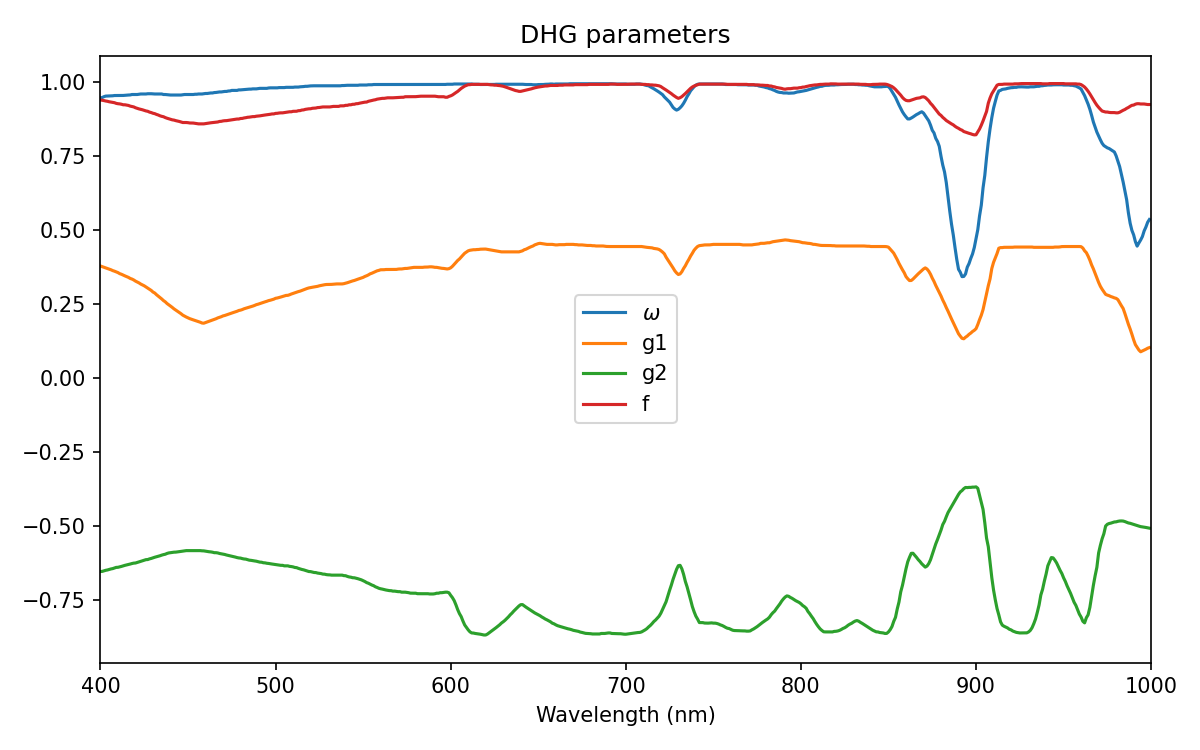

  Lambertian f_CR saved → ./fCR_lambertian.png


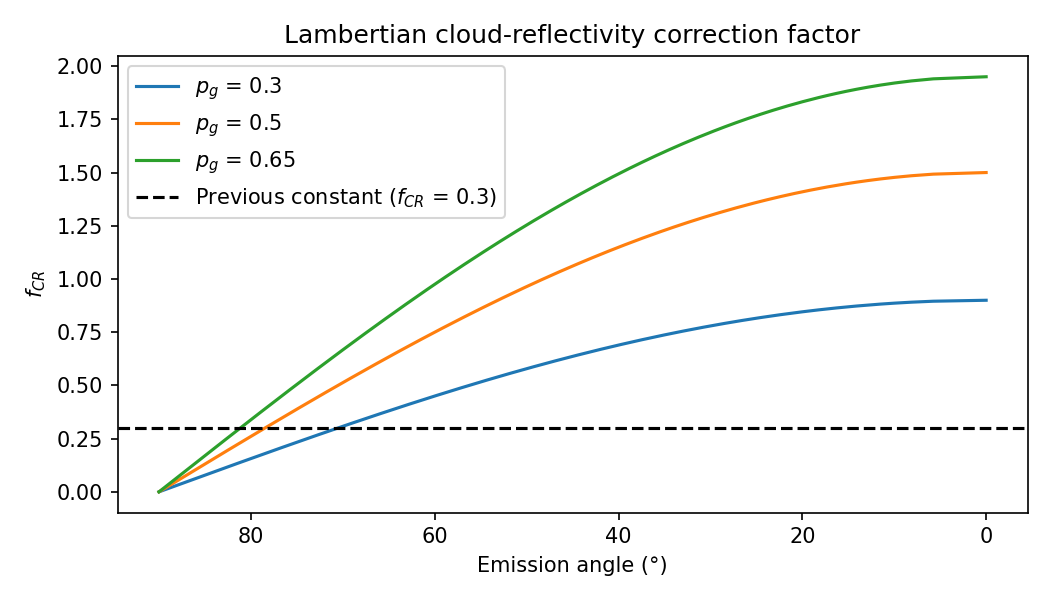

  Lambertian delta_ICR saved → ./delta_ICR_wavelength_Pg.png


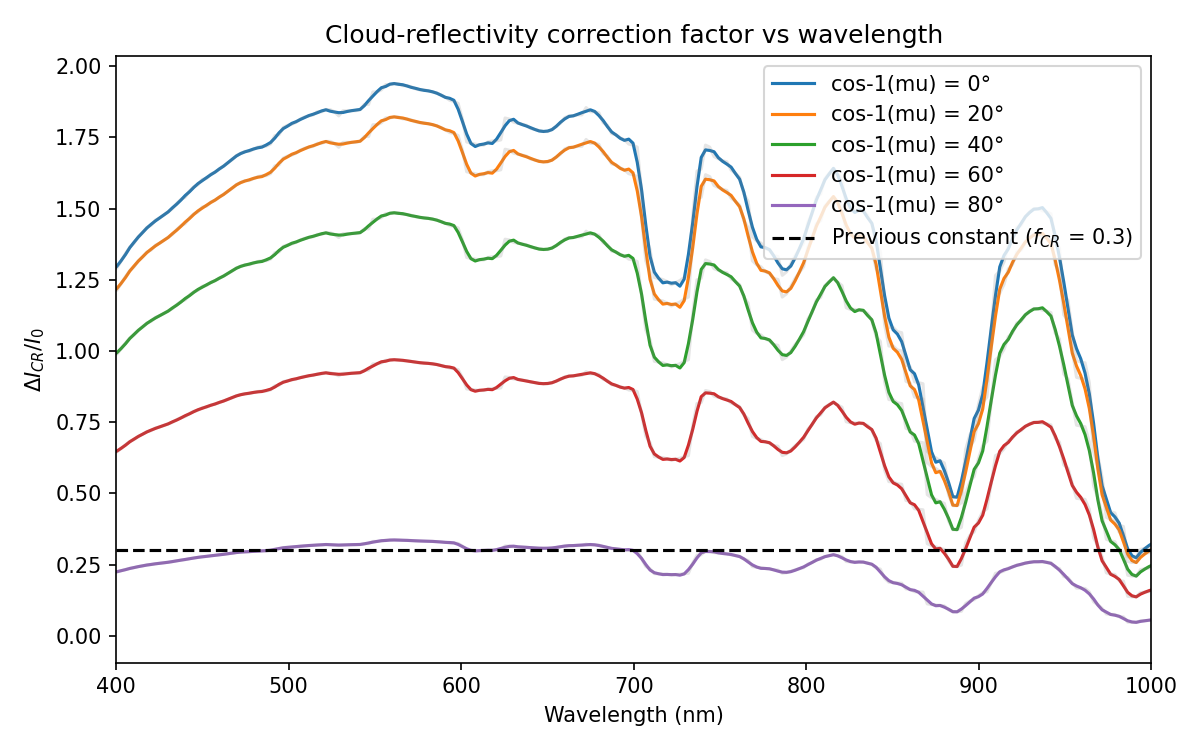

In [9]:
plot_DHG_parameters(*load_DHG_parameters(DHG_CSVS["omega"], DHG_CSVS["g1"],
                                          DHG_CSVS["g2"], DHG_CSVS["f"]),
                    save_path="./DHG_parameters.png")
display(Image("./DHG_parameters.png"))

plot_fCR_lambertian(save_path="./fCR_lambertian.png")
display(Image("./fCR_lambertian.png"))

if os.path.exists(PG_CSV):
    plot_delta_ICR(PG_CSV, save_path="./delta_ICR_wavelength_Pg.png")
    display(Image("./delta_ICR_wavelength_Pg.png"))

# Slow. For a quick look, pass every 10th wavelength, e.g.
# wavelengths_DHG[::10], omega[::10], ..., n_r=100, n_phi=60
# plot_delta_ICR_DHG(wavelengths_DHG, omega, g1, g2, f, h=flash_height_km,
#                    save_path="./delta_ICR_wavelength_DHG.png")
# display(Image("./delta_ICR_wavelength_DHG.png"))

## Part A: light curve extraction

Loads the frames, co-registers and flux-normalises them, builds the reference image, detects the flash, and runs aperture photometry on every frame.

Skip this section if you already have a light curve in DN or Watts (see the alternative inputs in Part B).

In [27]:
lc = extract_light_curve(
    frame_dir        = FRAME_DIR,
    pattern          = "frame*.png",
    aperture_radius  = aperture_radius,
    sky_inner        = sky_inner,
    sky_outer        = sky_outer,
    quiet_fraction   = quiet_fraction,
    savgol_window    = savgol_window,
    savgol_polyorder = savgol_polyorder,
    n_sigma          = n_sigma,
    flash_frames     = flash_frames,
)

  Loaded 171 frames
  Co-registered 171 frames
  Flux-normalised 171 frames
  Reference built from 46 quiet frames
  Flash detected in 93 frame(s): [48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140]
    Frame 48: centroid (row=175.4, col=443.7)
    Frame 49: centroid (row=175.8, col=443.9)
    Frame 50: centroid (row=174.3, col=443.2)
    Frame 51: centroid (row=174.7, col=441.7)
    Frame 52: centroid (row=175.2, col=442.0)
    Frame 53: centroid (row=173.3, col=441.6)
    Frame 54: centroid (row=175.8, col=439.5)
    Frame 55: centroid (row=175.2, col=440.3)
    Frame 56: centroid (row=175.2, col=444.0)
    Frame 57: centroid (

### Aperture diagnostic

Check that the green aperture contains the whole flash and that the orange sky annulus doesn't overlap the flash. If it does, change `aperture_radius`, `sky_inner`, or `sky_outer` in Settings and re-run from there.

  Aperture diagnostic saved → ./aperture_diagnostic.png


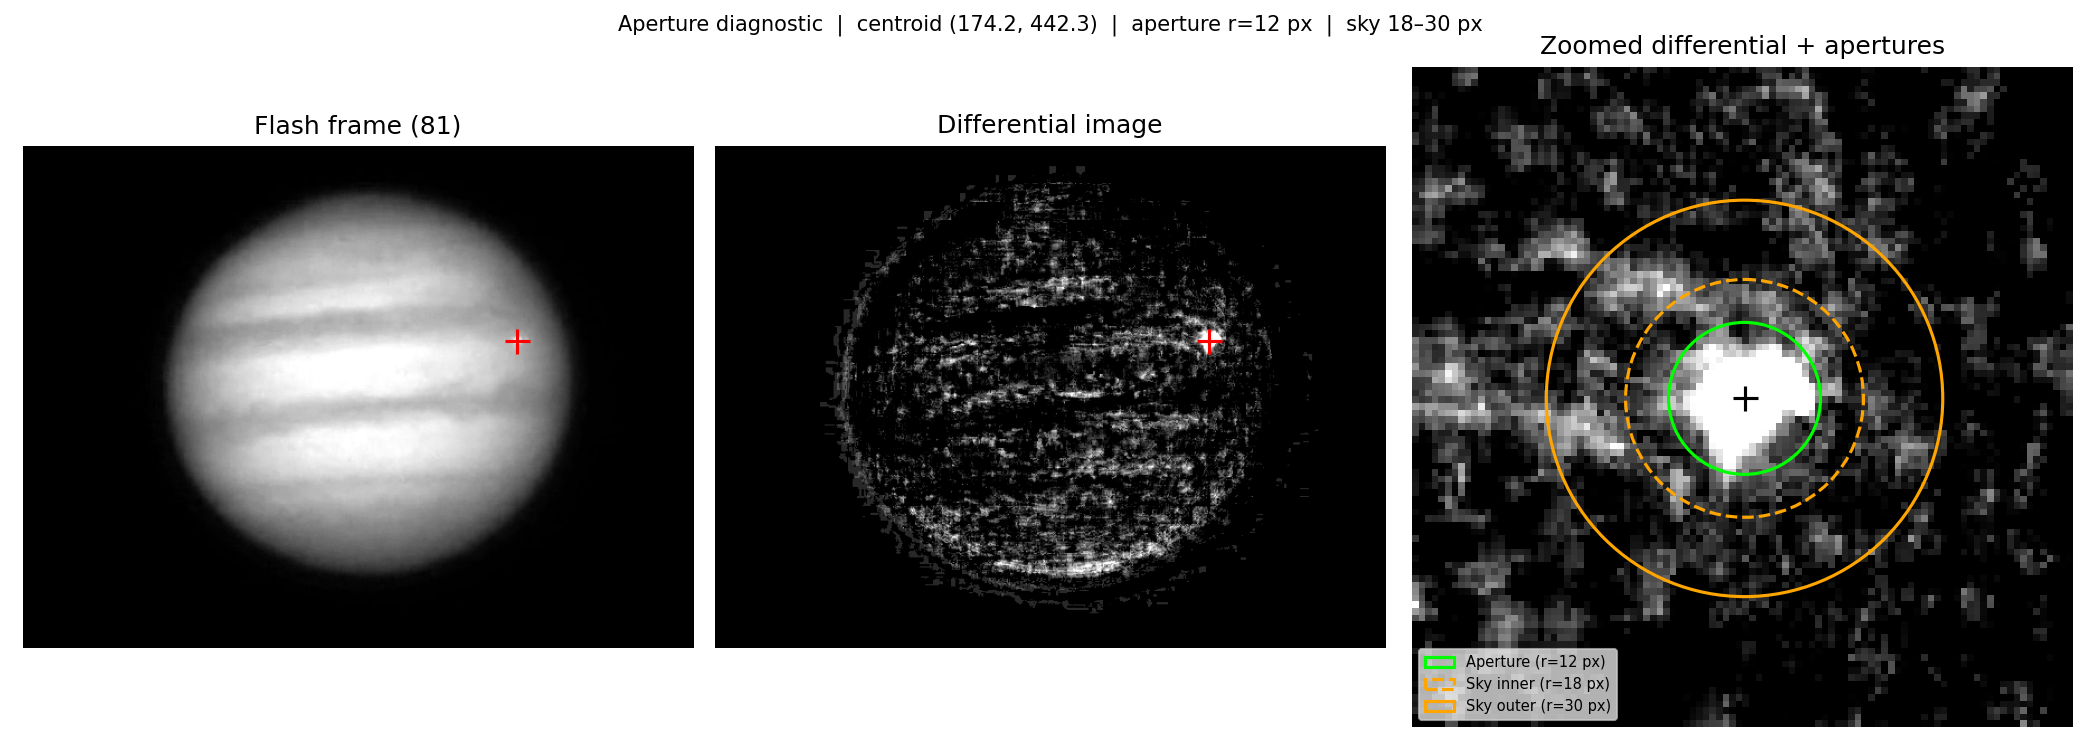

In [28]:
peak_idx = lc["peak_flash_idx"]
plot_aperture_diagnostic(
    peak_idx        = peak_idx,
    flash_frame     = lc["aligned_frames"][peak_idx],
    reference       = lc["reference"],
    flash_yx        = lc["flash_yx_per_frame"][peak_idx],
    aperture_radius = aperture_radius,
    sky_inner       = sky_inner,
    sky_outer       = sky_outer,
    save_path       = "./aperture_diagnostic.png",
)
display(Image("./aperture_diagnostic.png"))

### Plot Differential Image for Peak Flash Frame

  Flash difference image saved → ./flash_difference.png


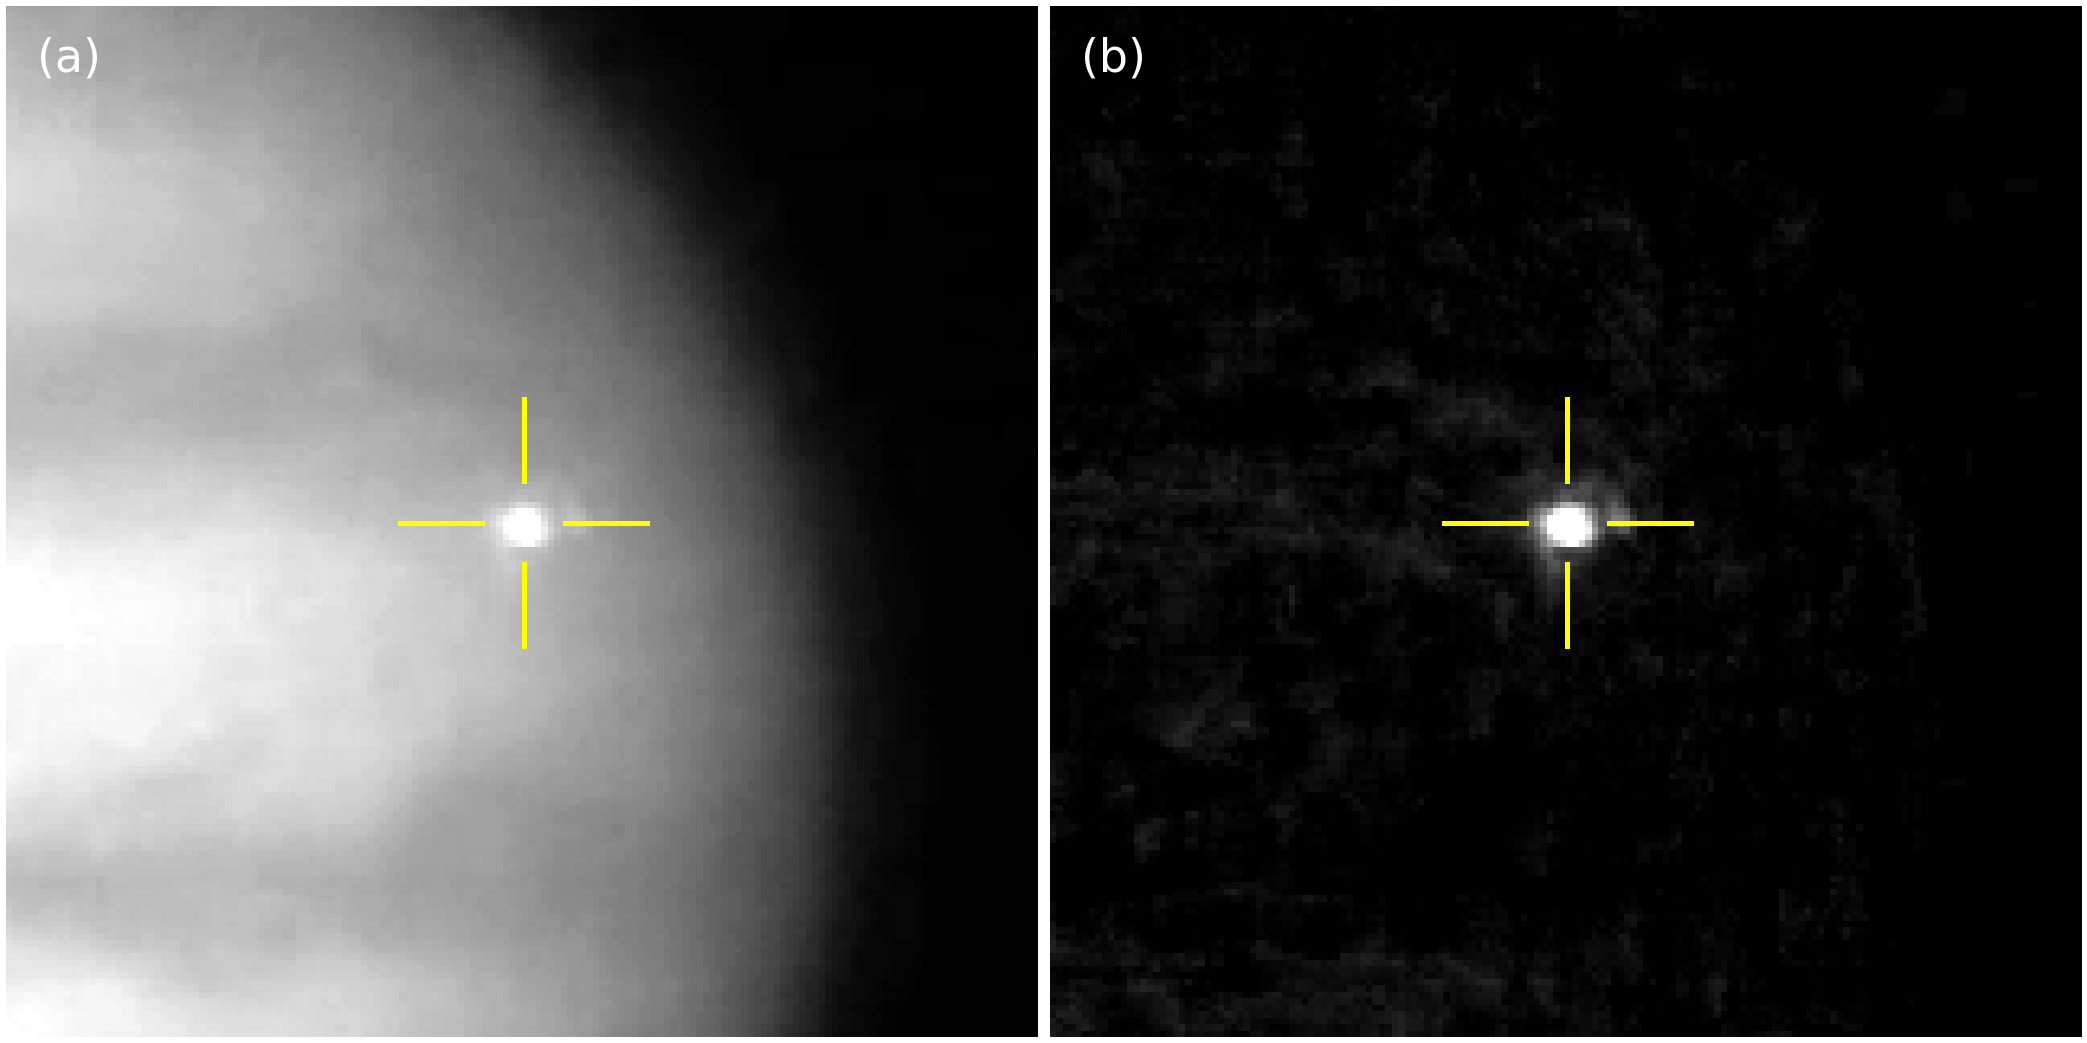

In [44]:
flash_no = lc["frame_numbers"][lc["peak_flash_idx"]] # or a pick a frame number by hand
pre_no   = lc["frame_numbers"].index(flash_no)

plot_flash_difference(
    flash_frame = lc["aligned_frames"][i_flash],
    background  = lc["reference"],             # median of the quiet frames
    flash_yx    = lc["flash_yx_per_frame"].get(i_flash, lc["flash_yx_per_frame"][lc["peak_flash_idx"]]),
    half_width  = 80,                          # None for the full frame
    save_path   = "./flash_difference.png",    # or .pdf
)
display(Image("./flash_difference.png"))

  Differential histogram saved → ./difference_histogram.png


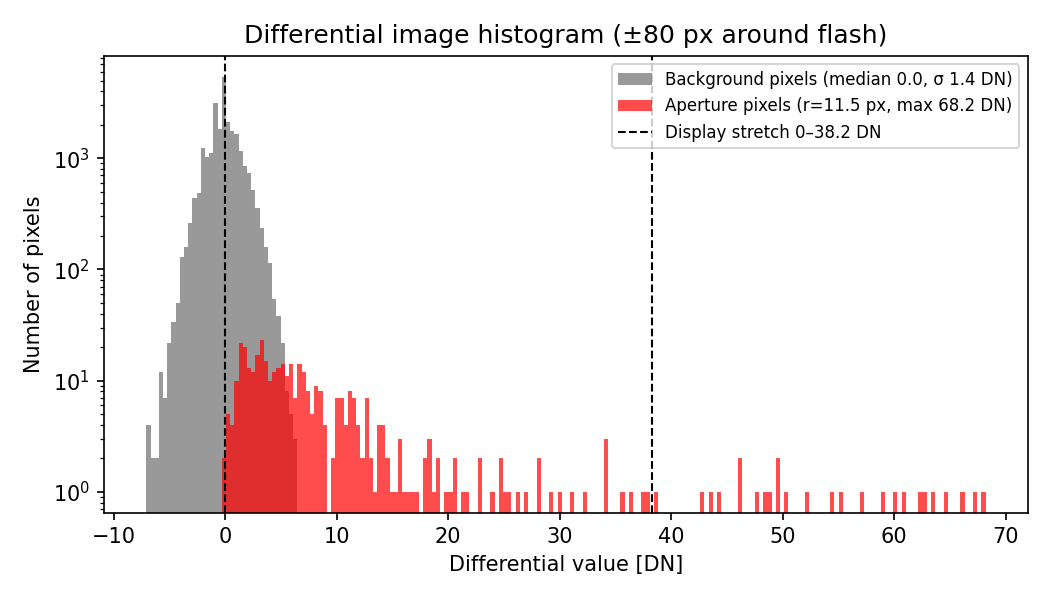

In [42]:
plot_difference_histogram(
    flash_frame     = lc["aligned_frames"][i_flash],
    background      = lc["reference"],
    flash_yx        = lc["flash_yx_per_frame"].get(i_flash, lc["flash_yx_per_frame"][lc["peak_flash_idx"]]),
    half_width      = 80,                # same as the image, or None for the full frame
    aperture_radius = aperture_radius,
    save_path       = "./difference_histogram.png",
)
display(Image("./difference_histogram.png"))

### Light curve in DN

  Light curve saved → ./light_curve_DNs.png


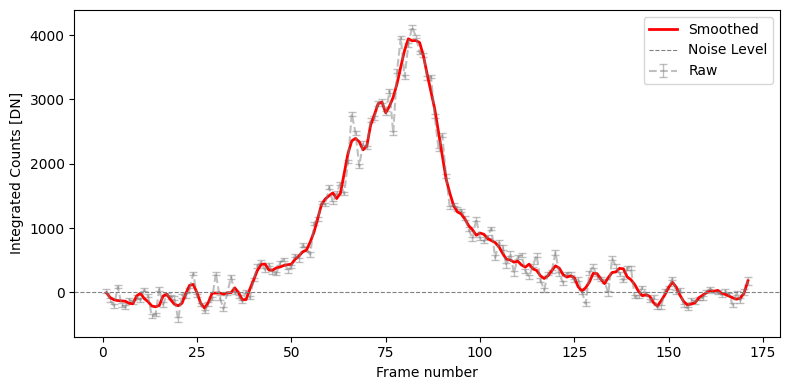

In [17]:
plot_light_curve_DN(lc, "./light_curve_DNs.png")

## Part B: impact characterisation

### Photometry inputs

By default these come from the Part A light curve. To start from a light curve CSV in DN instead, uncomment the matching lines below.
The DN-from-CSV path has not been tested.

In [18]:
# Default: from the Part A video extraction
I_star      = lc["I_star"]
I_Jupiter   = lc["I_Jupiter"]
I_star_peak = lc["I_star_peak"]

# # ALTERNATIVE: from a light curve CSV in DN
# df = pd.read_csv("light_curve_data.csv")       # change file name for specific case
# flux_DN = df["flux_DN"].values.astype(float)   # column name may need to be redefined
# I_star      = float(flux_DN[flux_DN > 0].sum())
# I_star_peak = float(flux_DN.max())
#
# # I_Jupiter, option 1: only if the CSV was originally produced by this pipeline
# meta = pd.read_csv("light_curve_metadata.csv")  # file with I_Jupiter, K_J and dt_frame_s
# I_Jupiter = float(meta["I_Jupiter_DN"][0])
#
# # I_Jupiter, option 2: from a single reference photo
# # (must be from the same camera used for the light curve)
# I_Jupiter = measure_I_jupiter("reference_frame.png")

### Impact model

In [19]:
results = jupiter_impact_model(
    I_star           = I_star,
    I_Jupiter        = I_Jupiter,
    I_star_peak      = I_star_peak,
    d_jupiter_au     = d_jupiter_au,
    dt_frame_s       = 1/fps,
    qe_csvs          = qe_csvs,
    transmission_csv = transmission_csv,
    solar_csv        = solar_csv,
    albedo_csv       = albedo_csv,
    fcr              = fcr,
    T_flash_range_K  = T_flash_range_K,
    v_kms_values     = v_kms_values,
    density_values   = density_values,
    V_jupiter        = V_jupiter,
    lam_min_nm       = lam_min_nm,
    lam_max_nm       = lam_max_nm,
)

### Alternative: light curve already in Watts

Use this **instead of** the cell above if your light curve CSV is already in Watts. It skips the K conversion and the cloud reflection correction.
The later output cells assume the Part A video extraction, so they may need changes. This function has not been tested.

- `light_curve_csv`: file name of the light curve data in Watts
- `time_col`, `flux_col`: column names for time and flux in that file
- `T_flash_range_K`: flash temperature range, may be set by the source of the light curve

In [ ]:
# results = jupiter_impact_model_from_watts(
#     light_curve_csv  = "light_curve_data.csv",
#     time_col         = "time_s",
#     flux_col         = "optical_energy_J",
#     qe_csvs          = qe_csvs,
#     transmission_csv = transmission_csv,
#     T_flash_range_K  = (3500.0, 10000.0),
#     v_impact_kms     = v_kms_values,
#     density_values   = density_values,
#     lam_min_nm       = lam_min_nm,
#     lam_max_nm       = lam_max_nm,
# )

### Results

In [20]:
print_results_table(results, v_kms_values, density_values)


  Parameter                                 Value
  ------------------------------------------------
  Conversion factor K                 1.269e+16 J
  Detected energy L*                  6.566e+13 J
  Flash temperature range            6000–14000 K
  Luminous energy (mean T)            4.693e+13 J
  Luminous energy (kt, mean)            11.216 kt
  Luminous energy range [J]       4.49e+13–5.24e+13 J
  Kinetic energy (mean T)             2.932e+14 J
  Kinetic energy (kt, mean)               70.1 kt
  Kinetic energy range [kt]          67.5–77.2 kt
  Luminous efficiency η (mean)             0.1600
  Luminous efficiency η (range)     0.1593–0.1621
  Mass at 60 km/s                     1.63e+05 kg
  Diameter at 60 km/s, 500 kg/m³          8.537 m
  Diameter at 60 km/s, 2500 kg/m³          4.993 m
  Diameter at 60 km/s, 5000 kg/m³          3.963 m
  Mass at 65 km/s                     1.39e+05 kg
  Diameter at 65 km/s, 500 kg/m³          8.093 m
  Diameter at 65 km/s, 2500 kg/m³         

## Outputs

These cells use the Part A video extraction (`lc`). They may need changes if you started from an extracted light curve.

### Impact stack

  Impact stack saved → ./impact_stack.png


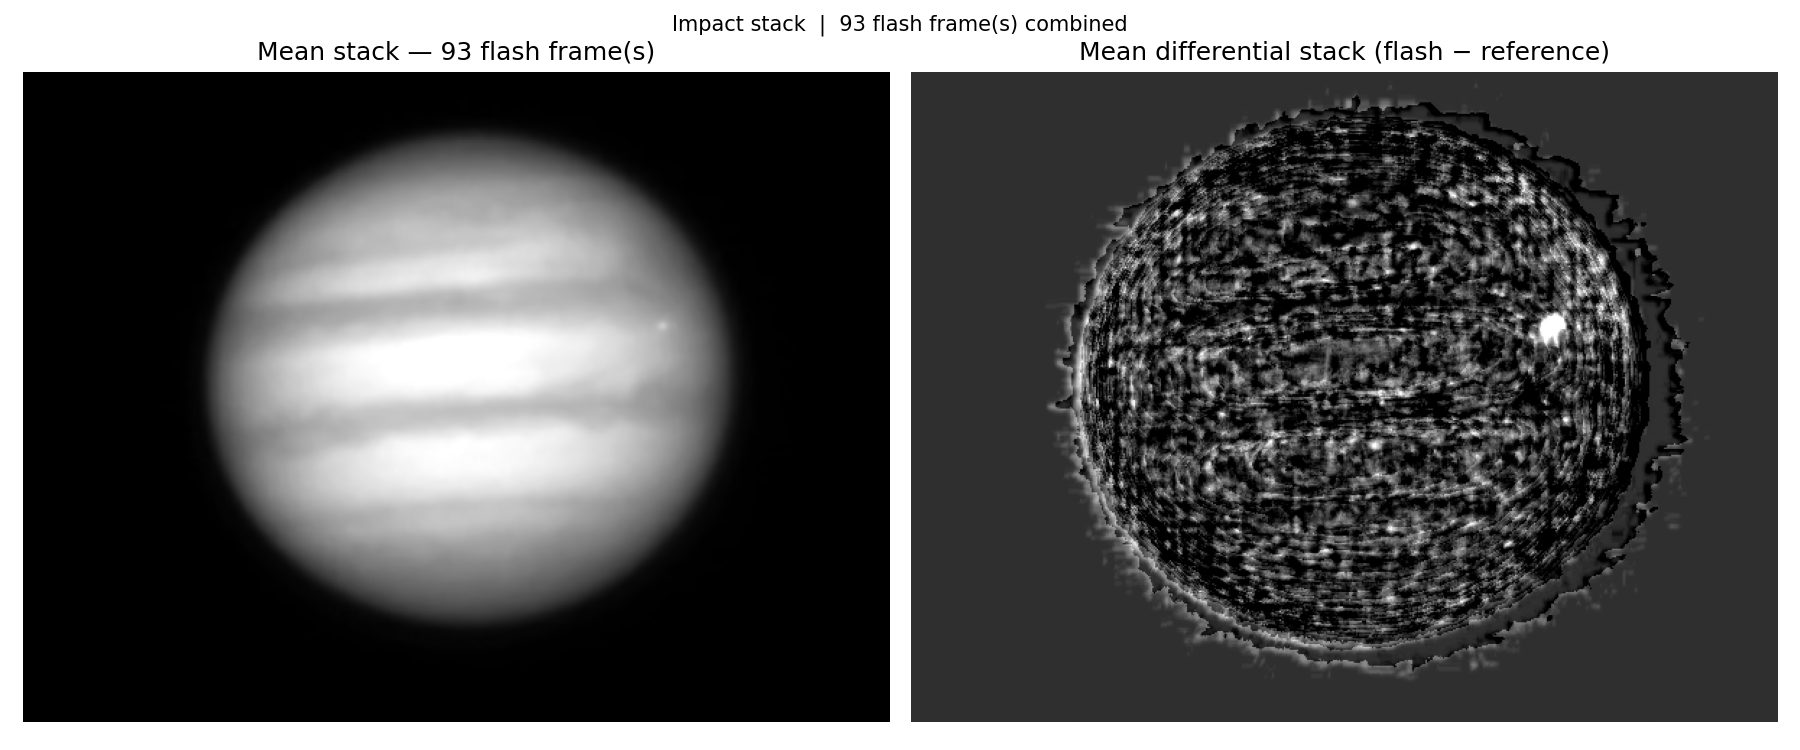

In [21]:
save_impact_stack(
    aligned_frames = lc["aligned_frames"],
    flash_indices  = lc["flash_indices"],
    reference      = lc["reference"],
    save_path      = "./impact_stack.png",
)
display(Image("./impact_stack.png"))

### Corrected light curves

Applies the cloud reflection and bolometric corrections frame by frame to the raw light curve, the smoothed light curve, and the uncertainties.

Cloud correction factor  : 0.3534
Bolometric factor (mean) : 0.715
  Corrected light curve saved → ./corrected_light_curve.png


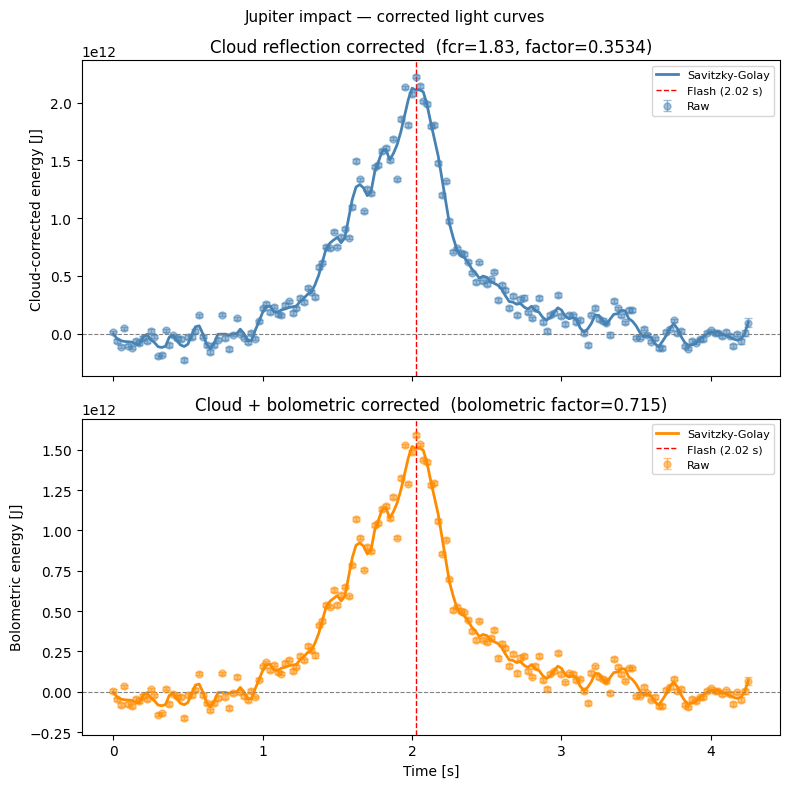

In [22]:
K          = results["K_J"]
dt_frame_s = float(1 / fps)
frame_nums = np.array(lc["frame_numbers"])
time_s     = (frame_nums - frame_nums[0]) / fps
flash_time = time_s[lc["peak_flash_idx"]]

lam = np.linspace(lam_min_nm, lam_max_nm, 1000)
C   = camera_filter_response(lam, qe_csvs, transmission_csv)

def correct(light_curve_DN):
    return corrected_light_curve(
        light_curve_DN  = light_curve_DN,
        I_Jupiter       = I_Jupiter,
        K               = K,
        wavelength_nm   = lam,
        C               = C,
        T_flash_range_K = (results["T_low_K"], results["T_high_K"]),
        fcr             = fcr,
    )

lc_corr        = correct(lc["light_curve"])
lc_corr_smooth = correct(lc["light_curve_smooth"])
lc_corr_unc    = correct(lc["uncertainties"])

print(f"Cloud correction factor  : {lc_corr['cloud_factor']:.4f}")
print(f"Bolometric factor (mean) : {lc_corr['bolometric_factor']:.3f}")

plot_corrected_light_curves(time_s, flash_time, lc_corr, lc_corr_smooth,
                            lc_corr_unc, fcr, "./corrected_light_curve.png")

### Save light curve data and metadata to CSV

`light_curve_metadata.csv` can be read back in Part B to rerun the model from the saved light curve.

In [23]:
df_out = pd.DataFrame({
    "frame_number":        frame_nums,
    "time_s":              time_s,
    "flux_DN":             lc["light_curve"],
    "flux_DN_smooth":      lc["light_curve_smooth"],
    "flux_DN_uncertainty": lc["uncertainties"],
})
for key in ["L_detected_J", "L_cloud_corrected_J", "L_bolometric_J"]:
    df_out[key]                  = lc_corr[key]
    df_out[f"{key}_smooth"]      = lc_corr_smooth[key]
    df_out[f"{key}_uncertainty"] = lc_corr_unc[key]

df_meta = pd.DataFrame({
    "I_Jupiter_DN":      [I_Jupiter],
    "K_J":               [K],
    "dt_frame_s":        [dt_frame_s],
    "cloud_factor":      [lc_corr["cloud_factor"]],
    "bolometric_factor": [lc_corr["bolometric_factor"]],
})

df_out.to_csv("./light_curve_data.csv", index=False)
df_meta.to_csv("./light_curve_metadata.csv", index=False)
print("Light curve data saved     → light_curve_data.csv")
print("Light curve metadata saved → light_curve_metadata.csv")
print(f"I_Jupiter = {I_Jupiter:.2f} DN | K = {K:.3e} J | dt = {dt_frame_s:.4f} s")
df_out.head()

Light curve data saved     → light_curve_data.csv
Light curve metadata saved → light_curve_metadata.csv
I_Jupiter = 8310785.14 DN | K = 1.269e+16 J | dt = 0.0250 s


,frame_number,time_s,flux_DN,flux_DN_smooth,flux_DN_uncertainty,L_detected_J,L_detected_J_smooth,L_detected_J_uncertainty,L_cloud_corrected_J,L_cloud_corrected_J_smooth,L_cloud_corrected_J_uncertainty,L_bolometric_J,L_bolometric_J_smooth,L_bolometric_J_uncertainty
0,1,0.000,16.870237,-7.958611,30.145192,2.575399e+10,-1.214956e+10,4.601945e+10,9.100193e+09,-4.293057e+09,1.626101e+10,6.504181e+09,-3.068377e+09,1.162223e+10
1,2,0.025,-120.506323,-82.332440,26.463202,-1.839642e+11,-1.256882e+11,4.039855e+10,-6.500387e+10,-4.441201e+10,1.427486e+10,-4.646022e+10,-3.174259e+10,1.020267e+10
2,3,0.050,-209.444356,-115.590890,29.489095,-3.197364e+11,-1.764603e+11,4.501786e+10,-1.129791e+11,-6.235238e+10,1.590709e+10,-8.074955e+10,-4.456512e+10,1.136928e+10
3,4,0.075,87.489273,-127.886451,24.045090,1.335606e+11,-1.952306e+11,3.670708e+10,4.719372e+10,-6.898488e+10,1.297047e+10,3.373077e+10,-4.930557e+10,9.270386e+09
4,5,0.100,-196.863877,-132.930949,26.032811,-3.005311e+11,-2.029315e+11,3.974152e+10,-1.061929e+11,-7.170600e+10,1.404269e+10,-7.589925e+10,-5.125043e+10,1.003674e+10
